# M14.0 — 4b-G3T frente a 4a-G3T (s123), validación G3T

Comparación **descriptiva** con regla de decisión fijada antes de ver resultados.

- **Modelo:** `M13_13_4b_G3T_s123` (`checkpoint_tag` de `configs/experiments/m13/train_m13_13_4bG3T_s123.json`), `val_predictions_embeddings.npz`.
- **Referencia:** `M13_13_4a_G3T_s123` (el mismo npz que M14.1 y M14.2).
- **Gates** como en M14.2: idx, y, N y RMSE física de la referencia (5,248 / 8,760 / 0,1677).
- **Umbrales:** ruido de semilla en D8–D10 recalculado exactamente como en M14.2 §1 (par G3 4a-aug s123/s124, máximo sobre D8, D9, D10); debe dar 3,548 / 1,607 / 4,734 %.
- **ΔRMSE %** de 4b frente a 4a por etiqueta en global, D1–D3, D4–D7, D8–D10 y D10; bootstrap emparejado por filas (B = 2000, `default_rng(140001)`), mismo orden de grupos que M14.2.

**Regla (fija):** se mantiene 4a salvo que 4b mejore en D8–D10 en chirp mass o χ_eff por más de 2 × ruido de semilla (7,10 % / 9,47 %), es decir, ΔRMSE < −umbral en la estimación puntual.

Solo se usa validación; ni calibración, ni test, ni eventos reales.

In [1]:
# 0. Parámetros, rutas y CONFIG (esta celda no carga datos)
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
# Read-only reuse, as in M14.1/M14.2: pinned G1 contract and tau30 of M13.1.
from scripts.m12.m12_5_3_posthoc_check import LABELS, digest, load_contract, npz_to_physical, require
from scripts.m13.m13_1_diagnostics import tau_newtonian

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
VAL_NPZ = 'val_predictions_embeddings.npz'
CFG_4B = ROOT / 'configs/experiments/m13/train_m13_13_4bG3T_s123.json'

# ---- Names and inputs (figures and tables take model and label names from here) --------------------------------
CONFIG = dict(
    models=dict(
        model=dict(tag=json.loads(CFG_4B.read_text())['outputs']['checkpoint_tag'], name='4b-G3T s123'),
        ref=dict(tag='M13_13_4a_G3T_s123', name='4a-G3T s123 (ref.)'),
        seed_a=dict(tag='M13_4a_G3aug_s123', name='4a-aug G3 s123'),
        seed_b=dict(tag='M13_4a_G3aug_s124', name='4a-aug G3 s124'),
    ),
    labels={'chirp_mass': 'chirp mass', 'total_mass': 'total mass', 'chi_eff': 'χ_eff'},
    units={'chirp_mass': 'M☉', 'total_mass': 'M☉', 'chi_eff': 'adim.'},
    colors=dict(model='#2a6fb0', thresh='#c4512b', zero='0.3', long_band='0.92'),
    fig_name='M14_0_drmse_4b_vs_4a_by_tau30_decile',
    title='ΔRMSE de 4b-G3T frente a 4a-G3T por decil de τ30 (val G3T, IC 95 % bootstrap emparejado)',
)
TAG_M, TAG_R = CONFIG['models']['model']['tag'], CONFIG['models']['ref']['tag']
TAG_SA, TAG_SB = CONFIG['models']['seed_a']['tag'], CONFIG['models']['seed_b']['tag']
PRED_M, PRED_R = M13_DIR / TAG_M / VAL_NPZ, M13_DIR / TAG_R / VAL_NPZ   # PRED_R: same npz as M14.1/M14.2
PRED_SA, PRED_SB = M13_DIR / TAG_SA / VAL_NPZ, M13_DIR / TAG_SB / VAL_NPZ   # M13_6 §3b pair (val G3)
OUT_DIR = M13_DIR / 'M14_0'
FIG_DIR = OUT_DIR / 'figures'
G3T_MARK = 'm13_13_g3t'
# -----------------------------------------------------------------------------------------------------------------

# Gates.
N_EXPECTED = 40000
RMSE_REF = [(5.248, 3), (8.760, 3), (0.1677, 4)]   # physical RMSE of 4a-G3T s123 on val G3T (value, decimals)
# Seed noise of the 4a-aug pair for chi_eff, as printed by M13_6 §3b (provenance check of the reused definition).
M13_6_NOISE_4A_CHI = {'D8': 1.1913, 'D9': 3.5565, 'D10': 4.734}
M13_6_NOISE_TOL = 5e-4
# D8-D10 seed noise (max over D8, D9, D10) expected from M14.2 §1, per label (value, decimals).
SEED_NOISE_EXPECTED = {'chirp_mass': (3.548, 3), 'total_mass': (1.607, 3), 'chi_eff': (4.734, 3)}
THRESH_EXPECTED = {'chirp_mass': (7.10, 2), 'chi_eff': (9.47, 2)}

# Fixed settings of this comparison.
N_BOOT = 2000
BLOCK = 200                                        # replicates per vectorised block (memory only; does not change draws)
SEED = 140001
SEED_K = 2.0
PRIMARY_LABELS = ['chirp_mass', 'chi_eff']
LONG_DECILES = ['D8', 'D9', 'D10']
REPORT_GROUPS = ['global', 'D1-D3', 'D4-D7', 'D8-D10', 'D10']
RUN_UTC = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
SUMMARY_PATH = OUT_DIR / f'M14_0_4b_vs_4a_G3T_summary_{RUN_UTC}.json'
print(DATA_ROOT)
print('Modelo:', TAG_M, '| referencia:', TAG_R)
print('Run stamp:', RUN_UTC)

/data/vserrano/cbc_pe_data
Modelo: M13_13_4b_G3T_s123 | referencia: M13_13_4a_G3T_s123
Run stamp: 20261112T153934Z


## 1. Ruido de semilla en D8–D10 (como M14.2 §1) y umbrales

In [2]:
# 1. Seed noise (G3 4a-aug pair); the compared models are not loaded here
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)']


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_val(path, name, ckpt_expected, g3t):
    # Same as load_val of M14.2 (cell 3). Only the keys below are read (allow_pickle=False).
    # g3t=True: memmap_dir must be under m13_13_g3t; g3t=False (G3 seed pair): it must not be (if recorded).
    require(path.exists(), f'{name}: missing {path}')
    with np.load(path, allow_pickle=False) as a:
        keys = set(a.files)
        f_s = a['pred_val'].astype(np.float64)
        y_raw = a['y_val']
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ckpt_name = Path(str(a['checkpoint_file'])).name if 'checkpoint_file' in keys else None
        memmap_dir = str(a['memmap_dir']) if 'memmap_dir' in keys else None
    y_s = y_raw.astype(np.float64)
    n = len(idx)
    check(f_s.shape == y_s.shape == (n, 3), f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal M11 train-only label stats')
    check(np.all(np.diff(idx) > 0), f'{name}: idx_val strictly ascending (no duplicates)')
    check(np.isfinite(f_s).all() and np.isfinite(y_s).all(), f'{name}: finite pred/y')
    if ckpt_name is None:
        warnings.warn(f'{name}: npz has no checkpoint_file; checkpoint not verified')
    else:
        check(ckpt_name == ckpt_expected, f'{name}: checkpoint is {ckpt_expected}')
    if g3t:
        check(memmap_dir is not None and G3T_MARK in memmap_dir, f'{name}: memmap_dir is under {G3T_MARK}')
    elif memmap_dir is not None:
        check(G3T_MARK not in memmap_dir, f'{name}: memmap_dir is G3 (not {G3T_MARK})')
    y, f, units = npz_to_physical(y_s, f_s, c_mean, c_std)
    check(units == 'standardized', f'{name}: npz pred/y standardized (trainer contract)')
    check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y')
    return dict(f=f, y=y, f_s=f_s, y_s=y_s, y_raw=y_raw, idx=idx, ckpt=ckpt_name, memmap_dir=memmap_dir)


def tau_deciles(Y):
    # tau30 deciles: code of M13_6 §3 / M14.1 cell 3, unchanged (Newtonian tau30 of the TRUE Mc, val quantile edges).
    tau30 = tau_newtonian(Y[:, 0])
    edges = np.quantile(tau30, np.linspace(0, 1, 11))
    return edges, np.clip(np.searchsorted(edges[1:-1], tau30, side='right'), 0, 9)


SA = load_val(PRED_SA, 'seed s123 (G3)', f'{TAG_SA}_final.pt', g3t=False)
SB = load_val(PRED_SB, 'seed s124 (G3)', f'{TAG_SB}_final.pt', g3t=False)
check(np.array_equal(SA['idx'], SB['idx']), 'seed pair: identical idx_val')
check(len(SA['idx']) == N_EXPECTED, f'seed pair: N = {N_EXPECTED}')
check(np.array_equal(SA['idx'], np.sort(splits['val'])), 'seed pair: idx_val equals val membership')
check(np.array_equal(SA['y_raw'], SB['y_raw']), 'seed pair: identical y_val (bitwise)')
Y_G3 = SA['y']
TAU_EDGES_G3, TDEC_G3 = tau_deciles(Y_G3)
DEC = [f'D{d + 1}' for d in range(10)]

noise_rows = []
for d, dn in enumerate(DEC):
    g = TDEC_G3 == d
    ra = np.sqrt(np.mean((SA['f'][g] - Y_G3[g])**2, 0))
    rb = np.sqrt(np.mean((SB['f'][g] - Y_G3[g])**2, 0))
    for j, lab in enumerate(LABELS):
        noise_rows.append(dict(decile=dn, label=lab, n=int(g.sum()), rmse_s123=ra[j], rmse_s124=rb[j],
                               noise_pct=100.0 * abs(ra[j] - rb[j]) / np.mean([ra[j], rb[j]])))
T_NOISE = pd.DataFrame(noise_rows)
for dn, v in M13_6_NOISE_4A_CHI.items():
    got = T_NOISE[(T_NOISE.decile == dn) & (T_NOISE.label == 'chi_eff')].noise_pct.iloc[0]
    check(abs(got - v) <= M13_6_NOISE_TOL, f'chi_eff seed noise {dn} = M13_6 §3b ({v})')

# D8-D10 seed noise (M13_6 §3b rule for the D8-D10 row: max over D8, D9, D10), per label; threshold 2x.
long = T_NOISE[T_NOISE.decile.isin(LONG_DECILES)]
SEED_NOISE_LONG = {lab: float(long[long.label == lab].noise_pct.max()) for lab in LABELS}
SEED_NOISE_ARGMAX = {lab: str(long[long.label == lab].set_index('decile').noise_pct.idxmax()) for lab in LABELS}
THRESH = {lab: SEED_K * SEED_NOISE_LONG[lab] for lab in LABELS}

# Asserts: same values as M14.2 §1 (3.548 / 1.607 / 4.734 %) and thresholds 7.10 / 9.47 %.
for lab, (v, d) in SEED_NOISE_EXPECTED.items():
    assert abs(round(SEED_NOISE_LONG[lab], d) - v) < 1e-9, f'seed noise {lab}: {SEED_NOISE_LONG[lab]:.4f} != {v}'
    checks.append(f'seed noise D8-D10 {lab} rounds to {v} (M14.2 §1)')
for lab, (v, d) in THRESH_EXPECTED.items():
    assert abs(round(THRESH[lab], d) - v) < 1e-9, f'threshold {lab}: {THRESH[lab]:.4f} != {v}'
    checks.append(f'threshold {lab} rounds to {v}')

T_THRESH = pd.DataFrame([dict(label=lab, noise_D8_D10_max_pct=SEED_NOISE_LONG[lab], from_decile=SEED_NOISE_ARGMAX[lab],
                              threshold_pct=THRESH[lab]) for lab in LABELS])
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_NOISE.pivot(index='decile', columns='label', values='noise_pct').reindex(DEC)[LABELS])
    display(T_THRESH)
print('Umbral (2 × ruido de semilla D8–D10):', {k: round(v, 3) for k, v in THRESH.items()})

label,chirp_mass,total_mass,chi_eff
decile,,,
D1,2.751,2.603,0.9046
D2,2.284,2.288,1.173
D3,0.3131,1.504,1.345
D4,0.4823,1.222,0.8397
D5,0.3756,0.8656,1.643
D6,2.375,3.882,1.047
D7,0.9819,0.7174,2.337
D8,3.548,1.607,1.191
D9,3.136,1.235,3.557


,label,noise_D8_D10_max_pct,from_decile,threshold_pct
0,chirp_mass,3.548,D8,7.097
1,total_mass,1.607,D8,3.214
2,chi_eff,4.734,D10,9.468


Umbral (2 × ruido de semilla D8–D10): {'chirp_mass': 7.097, 'total_mass': 3.214, 'chi_eff': 9.468}


## 2. Carga y gates

In [3]:
# 2. Load and GATES (require aborts on the first failure)
for name, p in (('pred/model', PRED_M), ('pred/ref', PRED_R)):
    require(p.exists(), f'Missing {name}: {p}')
sha = {'pred/model': digest(PRED_M), 'pred/ref': digest(PRED_R), 'pred/seed_a': digest(PRED_SA),
       'pred/seed_b': digest(PRED_SB)}
M = load_val(PRED_M, '4b', f'{TAG_M}_final.pt', g3t=True)
R = load_val(PRED_R, 'ref', f'{TAG_R}_final.pt', g3t=True)
IDX = M['idx']
check(np.array_equal(R['idx'], IDX), 'G1: identical idx_val (same rows, same order)')
check(len(IDX) == N_EXPECTED, f'G1: N = {N_EXPECTED}')
check(np.array_equal(IDX, np.sort(splits['val'])), 'G1: idx_val equals val membership')
check(M['y_raw'].dtype == R['y_raw'].dtype and np.array_equal(M['y_raw'], R['y_raw']), 'G1: identical y_val (bitwise)')
check(not np.array_equal(M['f_s'], R['f_s']), 'G1: 4b and reference predictions differ')
check(np.array_equal(IDX, SA['idx']), 'G3T val rows = G3 val rows of the seed pair')
check(np.allclose(M['y'], Y_G3, rtol=1e-6, atol=1e-6), 'G3T y_val = G3 y_val (shared labels)')
gates = {'G1': dict(n=int(len(IDX)), idx_identical=True, y_identical=True)}

# Physical RMSE of the reference reproduces 5.248 / 8.760 / 0.1677 (to the rounding).
Y = M['y']
rmse_ref_g3 = np.sqrt(np.mean((R['f'] - Y)**2, 0))
print('RMSE física de la referencia:', dict(zip(LABELS, rmse_ref_g3.round(5))))
for j, (v, d) in enumerate(RMSE_REF):
    check(abs(round(float(rmse_ref_g3[j]), d) - v) < 1e-9, f'G3: RMSE_ref {LABELS[j]} rounds to {v}')
gates['G3'] = dict(rmse_ref=rmse_ref_g3, expected=[v for v, _ in RMSE_REF])

# Groups on val G3T (same rows and labels as the seed pair, so the same decile edges).
TAU_EDGES, TDEC = tau_deciles(Y)
check(np.array_equal(TAU_EDGES, TAU_EDGES_G3) and np.array_equal(TDEC, TDEC_G3), 'tau30 deciles = those of section 1')
N = len(Y)
GROUPS = {**{k: TDEC == d for d, k in enumerate(DEC)}, 'D1-D3': TDEC <= 2, 'D4-D7': (TDEC >= 3) & (TDEC <= 6),
          'D8-D10': TDEC >= 7, 'global': np.ones(N, bool)}
check(sum(int(GROUPS[k].sum()) for k in ('D1-D3', 'D4-D7', 'D8-D10')) == N, 'tau groups partition val')
print('GATES passed:', len(checks), 'checks | n_val:', N)

RMSE física de la referencia: {'chirp_mass': np.float64(5.24798), 'total_mass': np.float64(8.75978), 'chi_eff': np.float64(0.16767)}
GATES passed: 65 checks | n_val: 40000


## 3. ΔRMSE de 4b frente a 4a (bootstrap emparejado) y veredicto

In [4]:
# 3. ΔRMSE % (4b vs 4a) and fixed decision rule
E2_M, E2_R = (M['f'] - Y)**2, (R['f'] - Y)**2
rng = np.random.default_rng(SEED)   # consumed in fixed order (as M14.2): D8-D10, global, D1-D3, D4-D7, then D1..D10


def drmse_boot(rows, rng):
    # Same as drmse_boot of M14.2 (cell 7): paired row bootstrap, one draw per replicate shared by the three labels.
    em, er = E2_M[rows], E2_R[rows]
    n = len(em)
    rm, rr = np.sqrt(em.mean(0)), np.sqrt(er.mean(0))
    reps = np.empty((N_BOOT, 3))
    for s in range(0, N_BOOT, BLOCK):
        m = min(BLOCK, N_BOOT - s)
        ii = rng.integers(0, n, size=(m, n))
        reps[s:s + m] = 100.0 * (np.sqrt(em[ii].mean(1)) / np.sqrt(er[ii].mean(1)) - 1.0)
    return rm, rr, 100.0 * (rm / rr - 1.0), reps


def drmse_table(group, rows, rng):
    rm, rr, pt, reps = drmse_boot(rows, rng)
    lo, hi = np.percentile(reps, [2.5, 97.5], axis=0)
    return [dict(group=group, label=lab, n=int(rows.sum()), rmse_ref=rr[j], rmse_model=rm[j], drmse_pct=pt[j],
                 ci95_lo=lo[j], ci95_hi=hi[j]) for j, lab in enumerate(LABELS)]


rows_all = []
for g in ['D8-D10', 'global', 'D1-D3', 'D4-D7'] + DEC:
    rows_all += drmse_table(g, GROUPS[g], rng)
T_ALL = pd.DataFrame(rows_all)
T_REPORT = T_ALL[T_ALL.group.isin(REPORT_GROUPS)].copy()
T_REPORT['group'] = pd.Categorical(T_REPORT.group, REPORT_GROUPS, ordered=True)
T_REPORT['label'] = pd.Categorical(T_REPORT.label, LABELS, ordered=True)
T_REPORT = T_REPORT.sort_values(['group', 'label']).reset_index(drop=True)
T_DEC = T_ALL[T_ALL.group.isin(DEC)].reset_index(drop=True)

# Decision rule (fixed): keep 4a unless 4b improves D8-D10 chirp_mass or chi_eff by more than 2x seed noise.
T_RULE = T_ALL[(T_ALL.group == 'D8-D10') & T_ALL.label.isin(PRIMARY_LABELS)].copy()
T_RULE['threshold_pct'] = T_RULE.label.map(THRESH)
T_RULE['improved_beyond_threshold'] = -T_RULE.drmse_pct > T_RULE.threshold_pct
ADOPT_4B = bool(T_RULE.improved_beyond_threshold.any())
VERDICT = ('Se adopta 4b: mejora en D8–D10 por más de 2 × ruido de semilla en '
           + ', '.join(CONFIG['labels'][l] for l in T_RULE[T_RULE.improved_beyond_threshold].label)
           if ADOPT_4B else 'Se mantiene 4a: 4b no mejora en D8–D10 por más de 2 × ruido de semilla en chirp mass ni en χ_eff')

with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_REPORT)
    display(T_RULE)
print('REGLA (D8–D10):')
for r in T_RULE.itertuples():
    print(f'  {r.label:10s} ΔRMSE {r.drmse_pct:+.2f} % [{r.ci95_lo:+.2f}; {r.ci95_hi:+.2f}] | umbral −{r.threshold_pct:.2f} % '
          f'→ {"supera" if r.improved_beyond_threshold else "no supera"}')
print('VEREDICTO:', VERDICT)

,group,label,n,rmse_ref,rmse_model,drmse_pct,ci95_lo,ci95_hi
0,global,chirp_mass,40000,5.248,5.284,0.695,0.1569,1.236
1,global,total_mass,40000,8.76,8.805,0.5115,-0.03874,1.093
2,global,chi_eff,40000,0.1677,0.167,-0.4101,-0.8981,0.09844
3,D1-D3,chirp_mass,12000,6.121,6.162,0.6661,-0.0972,1.496
4,D1-D3,total_mass,12000,10.31,10.4,0.8985,0.2011,1.648
5,D1-D3,chi_eff,12000,0.1808,0.1837,1.589,0.9176,2.232
6,D4-D7,chirp_mass,16000,5.397,5.43,0.6137,-0.08682,1.347
7,D4-D7,total_mass,16000,8.482,8.533,0.6066,-0.3441,1.644
8,D4-D7,chi_eff,16000,0.1513,0.1519,0.388,-0.2852,1.077
9,D8-D10,chirp_mass,12000,3.937,3.975,0.9683,-0.7893,2.732


,group,label,n,rmse_ref,rmse_model,drmse_pct,ci95_lo,ci95_hi,threshold_pct,improved_beyond_threshold
0,D8-D10,chirp_mass,12000,3.937,3.975,0.9683,-0.7893,2.732,7.097,False
2,D8-D10,chi_eff,12000,0.1746,0.1686,-3.425,-4.595,-2.161,9.468,False


REGLA (D8–D10):
  chirp_mass ΔRMSE +0.97 % [-0.79; +2.73] | umbral −7.10 % → no supera
  chi_eff    ΔRMSE -3.42 % [-4.59; -2.16] | umbral −9.47 % → no supera
VEREDICTO: Se mantiene 4a: 4b no mejora en D8–D10 por más de 2 × ruido de semilla en chirp mass ni en χ_eff


## 4. Figura: ΔRMSE por decil de τ30

Guardada: /data/vserrano/cbc_pe_data/results/M13_3/M14_0/figures/M14_0_drmse_4b_vs_4a_by_tau30_decile_20261112T153934Z.png
Guardada: /data/vserrano/cbc_pe_data/results/M13_3/M14_0/figures/M14_0_drmse_4b_vs_4a_by_tau30_decile_20261112T153934Z.pdf


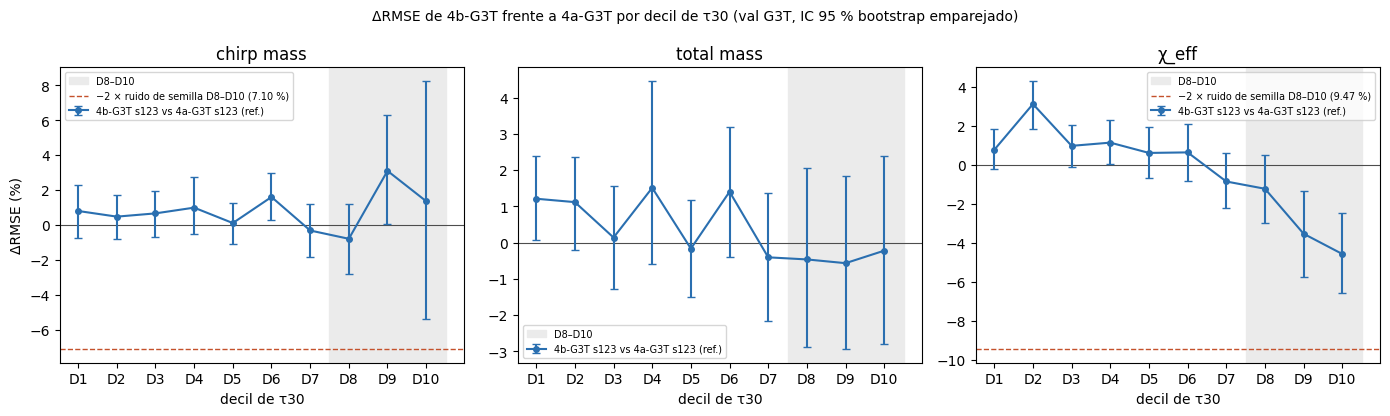

In [5]:
# 4. Figure: ΔRMSE % by tau30 decile with 95% bootstrap CI (names from CONFIG; never overwrites)
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
x = np.arange(1, 11)
for ax, lab in zip(axes, LABELS):
    t = T_DEC[T_DEC.label == lab].set_index('group').reindex(DEC)
    ax.axvspan(7.5, 10.5, color=CONFIG['colors']['long_band'], zorder=0, label='D8–D10')
    ax.axhline(0.0, color=CONFIG['colors']['zero'], lw=0.8)
    ax.errorbar(x, t.drmse_pct, yerr=[t.drmse_pct - t.ci95_lo, t.ci95_hi - t.drmse_pct], fmt='o-', ms=4, capsize=3,
                color=CONFIG['colors']['model'], label=f"{CONFIG['models']['model']['name']} vs {CONFIG['models']['ref']['name']}")
    if lab in PRIMARY_LABELS:
        ax.axhline(-THRESH[lab], color=CONFIG['colors']['thresh'], ls='--', lw=1,
                   label=f'−2 × ruido de semilla D8–D10 ({THRESH[lab]:.2f} %)')
    ax.set_title(CONFIG['labels'][lab])
    ax.set_xticks(x)
    ax.set_xticklabels(DEC)
    ax.set_xlabel('decil de τ30')
    ax.legend(fontsize=7, loc='best')
axes[0].set_ylabel('ΔRMSE (%)')
fig.suptitle(CONFIG['title'], fontsize=10)
fig.tight_layout()
FIG_PATHS = [FIG_DIR / f"{CONFIG['fig_name']}_{RUN_UTC}.{ext}" for ext in ('png', 'pdf')]
for p in FIG_PATHS:
    require(not p.exists(), f'Refusing to overwrite {p}')
    fig.savefig(p, dpi=200, bbox_inches='tight')
    print('Guardada:', p)
plt.show()

## 5. Resumen JSON

In [6]:
# 5. JSON summary (mode 'x': fails if the file exists)
def _py(o):
    if isinstance(o, dict):
        return {str(k): _py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_py(v) for v in o]
    if isinstance(o, np.ndarray):
        return _py(o.tolist())
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    return o


summary = dict(
    experiment='M14.0 4b-G3T vs 4a-G3T (s123), val G3T, descriptive with fixed decision rule',
    run_utc=RUN_UTC,
    model=dict(tag=TAG_M, config=str(CFG_4B.relative_to(ROOT)), pred=str(PRED_M), sha256=sha['pred/model']),
    reference=dict(tag=TAG_R, pred=str(PRED_R), sha256=sha['pred/ref']),
    seed_pair=dict(tags=[TAG_SA, TAG_SB], sha256=[sha['pred/seed_a'], sha['pred/seed_b']]),
    split='validation', n=N, labels=LABELS,
    gates=gates, checks=checks,
    bootstrap=dict(n_boot=N_BOOT, seed=SEED, rng='numpy.default_rng', paired='rows', ci='percentile 95%',
                   group_order=['D8-D10', 'global', 'D1-D3', 'D4-D7'] + DEC),
    seed_noise_D8_D10_pct=SEED_NOISE_LONG, seed_noise_from_decile=SEED_NOISE_ARGMAX, threshold_pct=THRESH,
    rule='keep 4a unless 4b improves D8-D10 in chirp_mass or chi_eff by more than 2 x seed noise (point estimate)',
    rule_rows=T_RULE.to_dict('records'), adopt_4b=ADOPT_4B, verdict=VERDICT,
    drmse=T_REPORT.astype({'group': str, 'label': str}).to_dict('records'),
    drmse_by_decile=T_DEC.to_dict('records'),
    figures=[str(p) for p in FIG_PATHS],
)
OUT_DIR.mkdir(parents=True, exist_ok=True)
with open(SUMMARY_PATH, 'x') as fh:
    json.dump(_py(summary), fh, indent=2, ensure_ascii=False)
print('Guardado:', SUMMARY_PATH)

Guardado: /data/vserrano/cbc_pe_data/results/M13_3/M14_0/M14_0_4b_vs_4a_G3T_summary_20261112T153934Z.json


## Lectura (12-11-2026)
**Regla fijada: se mantiene 4a.** 4b-G3T frente a 4a-G3T en D8–D10: chirp +0,97 % [−0,79; +2,73], χ_eff −3,43 % [−4,60; −2,16], frente a umbrales de −7,10 % y −9,47 % (2 × ruido de semilla de 4a en D8–D10, par G3).
- Global: +0,70 / +0,51 / −0,41 %. 4b es algo peor en señales cortas (χ_eff D1–D3 +1,59 %) y algo mejor en χ_eff de señales largas (D10 −4,57 %). Todo dentro del ruido de semilla.
- Mismo patrón que M13.6 (G3) y que el banco de filtros (M14.2): las mejoras en χ_eff de señales largas quedan en el borde del ruido de semilla con una semilla.
- Coste de entrenamiento de 4b ~4× el de 4a → 4a como arquitectura base.